# Multi-Basin Rainfall–Runoff LSTM — Meteorology-Only Model

This notebook trains one LSTM across the configured catchments using **meteorological time series only**. Static catchment attributes (elevation, soil, vegetation, slope, and related metadata) are not required, read, normalized, or passed to the model.

The experiment retains the original notebook's train/validation/test split, training-only normalization, basin-balanced sampling and loss, early stopping, held-out test metrics, saved predictions, and interactive hydrograph explorer.

**Important:** This is a meteorology-only *multi-basin* model. It does not receive basin attributes or a basin ID as input; the shared model learns from meteorological sequences across all configured catchments.


## 1. Configuration

Configure the basin CSV files and meteorological predictors here. The CSV files only need a timestamp, the meteorological columns below, and observed discharge; static attribute columns are not needed.


In [1]:
# -----------------------------
# Basin files and meteorology-only model settings
# -----------------------------
CSV_FILES = [
    "CAN_01AD003.csv",
    "CAN_01BJ003.csv",
    "CAN_02CF007.csv",
    "CAN_05BB001.csv",
    "USA_01013500.csv",
    "USA_01073000.csv",
    "USA_02015700.csv",
    "USA_03346000.csv",
    "USA_04216418.csv",
    "USA_07068000.csv",
]

MET_COLS = [
    "Precipitation_mm_day",
    "Temperature_C",
    "Air_Pressure_Pa",
    "Longwave_Rad_W_m2",
    "Shortwave_Rad_W_m2",
    "Specific_Humidity_kg_kg",
    "Wind_Speed_m_s",
]

TARGET_COL = "Observed_Discharge_cfs"
DATE_COL_CANDIDATES = ["Timestamp", "Date", "datetime", "time"]
FORCING_HOURS_COL = "Forcing_Hour_Count"  # optional; used to flag incomplete daily forcing

LOOKBACK_DAYS = 365
TEST_DAYS = 5 * 365           # final five years, using daily rows
VALIDATION_DAYS = 3 * 365     # three years immediately before the test period
USE_TARGET_DAY_METEOROLOGY = True

HIDDEN_SIZE = 128
DROPOUT = 0.10
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
MAX_EPOCHS = 40
EARLY_STOPPING_PATIENCE = 6
MIN_VALIDATION_IMPROVEMENT = 1e-4
BATCH_SIZE = 256
GRAD_CLIP_NORM = 1.0

MODEL_PATH = "multibasin_lstm_model_v2.pth"
NORMALIZATION_PATH = "multibasin_norm_stats_v2.npz"
METRICS_PATH = "multibasin_test_metrics_v2.csv"
PREDICTIONS_PATH = "multibasin_test_predictions_v2.csv"


## 2. Imports and reproducibility
Set random seeds and choose the available device. Mixed precision is enabled only when CUDA is available.

In [2]:
%pip install --ignore-installed setuptools

Looking in links: /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/x86-64-v4, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/x86-64-v3, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/generic, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/generic
Processing /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/generic/setuptools-84.2.1+computecanada-py3-none-any.whl
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install numpy pandas matplotlib scikit-learn ipywidgets ipykernel torch

Looking in links: /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/x86-64-v4, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/x86-64-v3, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/generic, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/generic
Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
import copy
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
# Prefer reproducibility over the fastest possible cuDNN algorithm selection.
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print(f"Device: {device} | Mixed precision: {USE_AMP}")


Device: cuda | Mixed precision: True


## 3. Find or upload the basin CSV files
All ten configured basins are required for the intended multi-basin experiment. If files are missing in Colab, this cell opens an upload dialog for the missing files.

In [5]:
# Look for the expected CSV files in the current notebook directory.
missing_files = [name for name in CSV_FILES if not Path(name).exists()]
if missing_files:
    print("CSV files not yet found:")
    for name in missing_files:
        print(f"  - {name}")
    try:
        from google.colab import files
        print("\nSelect the missing basin CSV files in the upload dialog.")
        files.upload()
    except ImportError:
        print(
            "\nThis notebook is not running in Google Colab. Copy the missing CSV files "
            "into the notebook's working directory and run this cell again."
        )

missing_files = [name for name in CSV_FILES if not Path(name).exists()]
if missing_files:
    raise FileNotFoundError(
        "The following required basin files are missing: " + ", ".join(missing_files)
        + ". Upload all configured CSVs or update CSV_FILES in Section 1."
    )

print(f"Found all {len(CSV_FILES)} basin CSV files.")


Found all 10 basin CSV files.


## 4. Load and audit the data

This step checks required meteorological and discharge columns, timestamp uniqueness, daily continuity, missing values, and incomplete forcing days. Static catchment attributes are intentionally ignored. Windows containing missing meteorological inputs, incomplete daily forcing, or a date gap are excluded from training/evaluation.


In [6]:
def find_date_column(columns):
    """Find a likely date/time field without assuming one exact column spelling."""
    lower_to_original = {str(col).lower(): col for col in columns}
    for candidate in DATE_COL_CANDIDATES:
        if candidate.lower() in lower_to_original:
            return lower_to_original[candidate.lower()]
    for col in columns:
        low = str(col).lower()
        if "time" in low or "date" in low:
            return col
    raise ValueError("Could not find a timestamp/date column.")


def load_and_audit_csv(path):
    """Load one basin file, validate its schema, and retain raw values for later splits."""
    df = pd.read_csv(path)
    date_col = find_date_column(df.columns)

    required = MET_COLS + [TARGET_COL]
    missing_cols = [col for col in required if col not in df.columns]
    if missing_cols:
        raise ValueError(f"{path} is missing required columns: {missing_cols}")

    df = df.copy()
    df["Timestamp"] = pd.to_datetime(df[date_col], errors="coerce")
    if df["Timestamp"].isna().any():
        bad_rows = int(df["Timestamp"].isna().sum())
        raise ValueError(f"{path} has {bad_rows} timestamp value(s) that could not be parsed.")

    df = df.sort_values("Timestamp").reset_index(drop=True)
    duplicate_count = int(df["Timestamp"].duplicated().sum())
    if duplicate_count:
        raise ValueError(f"{path} has {duplicate_count} duplicate timestamp(s); resolve them before training.")

    # Convert model input/target columns to numeric. Unparseable entries become NaN and are audited below.
    for col in MET_COLS + [TARGET_COL]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df[MET_COLS + [TARGET_COL]] = df[MET_COLS + [TARGET_COL]].replace(
        [np.inf, -np.inf], np.nan
    )

    # Count non-daily gaps. Windows crossing such a gap will be excluded later.
    day_diffs = df["Timestamp"].diff().dt.total_seconds().div(86400).to_numpy()
    gap_flags = np.zeros(len(df), dtype=bool)
    if len(df) > 1:
        gap_flags[1:] = ~np.isclose(day_diffs[1:], 1.0)
    n_gap_edges = int(gap_flags.sum())

    missing_met_count = int(df[MET_COLS].isna().any(axis=1).sum())
    missing_target_count = int(df[TARGET_COL].isna().sum())
    partial_forcing_count = 0
    if FORCING_HOURS_COL in df.columns:
        forcing_hours = pd.to_numeric(df[FORCING_HOURS_COL], errors="coerce")
        partial_forcing_count = int((forcing_hours.notna() & (forcing_hours != 24)).sum())

    raw = {
        "name": Path(path).name,
        "df": df,
        "x_raw": df[MET_COLS].to_numpy(dtype=np.float64),
        "y_raw": df[TARGET_COL].to_numpy(dtype=np.float64),
        "timestamps": df["Timestamp"].to_numpy(dtype="datetime64[ns]"),
        "gap_flags": gap_flags,
        "missing_met_rows": missing_met_count,
        "missing_target_rows": missing_target_count,
        "partial_forcing_rows": partial_forcing_count,
        "gap_edges": n_gap_edges,
    }

    # Make the per-day input-validity flag. Where available, require full 24-hour forcing coverage.
    input_day_valid = np.isfinite(raw["x_raw"]).all(axis=1)
    if FORCING_HOURS_COL in df.columns:
        hours = pd.to_numeric(df[FORCING_HOURS_COL], errors="coerce").to_numpy(dtype=float)
        # A missing or partial Forcing_Hour_Count means the daily met aggregate may be incomplete.
        input_day_valid &= np.isfinite(hours) & np.isclose(hours, 24.0)
    raw["input_day_valid"] = input_day_valid
    return raw


basins = [load_and_audit_csv(path) for path in CSV_FILES]

# A compact audit table helps spot differences before looking at model scores.
audit_rows = []
for basin in basins:
    df = basin["df"]
    valid_q = df[TARGET_COL].dropna()
    annualized_precip = df["Precipitation_mm_day"].mean(skipna=True) * 365.25
    audit_rows.append({
        "Basin": basin["name"],
        "Rows": len(df),
        "Start date": df["Timestamp"].min().date(),
        "End date": df["Timestamp"].max().date(),
        "Missing met rows": basin["missing_met_rows"],
        "Missing discharge rows": basin["missing_target_rows"],
        "Partial forcing rows": basin["partial_forcing_rows"],
        "Non-daily gap edges": basin["gap_edges"],
        "Annualized mean precipitation (mm/year)": annualized_precip,
        "Mean discharge (cfs)": valid_q.mean(),
        "Median discharge (cfs)": valid_q.median(),
        "Max discharge (cfs)": valid_q.max(),
    })

audit_df = pd.DataFrame(audit_rows)
display(audit_df.round(3))



,Basin,Rows,Start date,End date,Missing met rows,Missing discharge rows,Partial forcing rows,Non-daily gap edges,Annualized mean precipitation (mm/year),Mean discharge (cfs),Median discharge (cfs),Max discharge (cfs)
0,CAN_01AD003.csv,24930,1951-09-30,2019-12-31,0,1,0,0,999.133,899.711,448.495,18151.704
1,CAN_01BJ003.csv,20181,1964-09-30,2019-12-31,0,1,0,0,1018.220,380.762,140.199,8298.931
2,CAN_02CF007.csv,21734,1960-06-30,2019-12-31,0,25,0,0,826.787,107.030,53.325,3114.748
3,CAN_05BB001.csv,25568,1949-12-31,2019-12-31,0,1,0,0,570.878,1369.688,603.880,16456.604
4,USA_01013500.csv,25568,1949-12-31,2019-12-31,0,1,0,0,979.468,1521.120,824.998,17899.966
5,USA_01073000.csv,25568,1949-12-31,2019-12-31,0,1,2,0,1116.447,20.746,11.000,941.998
6,USA_02015700.csv,21703,1960-07-31,2019-12-31,0,1,2,0,982.902,154.340,84.000,8699.984
7,USA_03346000.csv,25568,1949-12-31,2019-12-31,0,1,2,0,1005.331,295.095,51.000,22499.958
8,USA_04216418.csv,15433,1977-09-30,2019-12-31,0,1,2,0,1052.945,119.528,66.000,3199.994
9,USA_07068000.csv,25568,1949-12-31,2019-12-31,0,1,2,0,1092.797,2889.689,1989.996,170999.678


## 5. Create training, validation, and test periods
For each basin, the final five years are test data; the three years immediately before them are validation data; all earlier rows are training data. The validation years guide early stopping. The test period is not used to fit any scaler or choose the best epoch. The split follows the original notebook’s row-based approach, assuming daily records.

In [7]:
# Use per-basin row indices so records can start/end on different dates.
for basin in basins:
    n = len(basin["df"])
    test_start = n - TEST_DAYS
    val_start = test_start - VALIDATION_DAYS
    train_end = val_start

    earliest_target_idx = LOOKBACK_DAYS - 1 if USE_TARGET_DAY_METEOROLOGY else LOOKBACK_DAYS
    if train_end <= earliest_target_idx:
        raise ValueError(
            f"{basin['name']} has only {n} rows, which is insufficient for the configured "
            f"{LOOKBACK_DAYS}-day lookback, {VALIDATION_DAYS}-day validation period, "
            f"and {TEST_DAYS}-day test period. Reduce these settings or provide more history."
        )

    basin["train_end"] = train_end
    basin["val_start"] = val_start
    basin["test_start"] = test_start

split_rows = []
for basin in basins:
    df = basin["df"]
    split_rows.append({
        "Basin": basin["name"],
        "Training through": df.loc[basin["train_end"] - 1, "Timestamp"].date(),
        "Validation start": df.loc[basin["val_start"], "Timestamp"].date(),
        "Validation end": df.loc[basin["test_start"] - 1, "Timestamp"].date(),
        "Test start": df.loc[basin["test_start"], "Timestamp"].date(),
        "Test end": df.loc[len(df) - 1, "Timestamp"].date(),
    })

display(pd.DataFrame(split_rows))


,Basin,Training through,Validation start,Validation end,Test start,Test end
0,CAN_01AD003.csv,2012-01-02,2012-01-03,2015-01-01,2015-01-02,2019-12-31
1,CAN_01BJ003.csv,2012-01-02,2012-01-03,2015-01-01,2015-01-02,2019-12-31
2,CAN_02CF007.csv,2012-01-02,2012-01-03,2015-01-01,2015-01-02,2019-12-31
3,CAN_05BB001.csv,2012-01-02,2012-01-03,2015-01-01,2015-01-02,2019-12-31
4,USA_01013500.csv,2012-01-02,2012-01-03,2015-01-01,2015-01-02,2019-12-31
5,USA_01073000.csv,2012-01-02,2012-01-03,2015-01-01,2015-01-02,2019-12-31
6,USA_02015700.csv,2012-01-02,2012-01-03,2015-01-01,2015-01-02,2019-12-31
7,USA_03346000.csv,2012-01-02,2012-01-03,2015-01-01,2015-01-02,2019-12-31
8,USA_04216418.csv,2012-01-02,2012-01-03,2015-01-01,2015-01-02,2019-12-31
9,USA_07068000.csv,2012-01-02,2012-01-03,2015-01-01,2015-01-02,2019-12-31


## 6. Fit normalization statistics on training data only

Meteorological means/scales, global discharge mean/scale, and per-basin discharge standard deviations are estimated from training data only. Constant meteorological features get scale 1 rather than dividing by a near-zero number.


In [8]:
# Pool only the training rows from every basin when fitting meteorological and target scalers.
train_x_parts = []
train_y_parts = []
basin_train_std_cfs = {}

for basin in basins:
    train_end = basin["train_end"]
    train_x_parts.append(basin["x_raw"][:train_end])
    train_y_parts.append(basin["y_raw"][:train_end])

    y_train = basin["y_raw"][:train_end]
    y_train = y_train[np.isfinite(y_train)]
    if len(y_train) < 2:
        raise ValueError(f"{basin['name']} has fewer than two valid training discharge values.")
    basin_train_std_cfs[basin["name"]] = float(np.std(y_train, ddof=0))

train_x_all = np.vstack(train_x_parts)
train_y_all = np.concatenate(train_y_parts)

mean_x = np.nanmean(train_x_all, axis=0)
std_x = np.nanstd(train_x_all, axis=0)
std_x = np.where(np.isfinite(std_x) & (std_x > 1e-8), std_x, 1.0)
if not np.isfinite(mean_x).all():
    bad_features = [MET_COLS[i] for i, value in enumerate(mean_x) if not np.isfinite(value)]
    raise ValueError(f"These meteorological features have no valid training data: {bad_features}")

finite_train_y = train_y_all[np.isfinite(train_y_all)]
if len(finite_train_y) < 2:
    raise ValueError("Not enough valid training discharge values across basins.")
mean_y = float(np.mean(finite_train_y))
std_y = float(np.std(finite_train_y, ddof=0))
if not np.isfinite(std_y) or std_y <= 1e-8:
    raise ValueError("Global training discharge standard deviation is zero or invalid.")

# Convert raw per-basin discharge standard deviations to the globally normalized target scale.
basin_std_scaled = {
    name: max(std_cfs / std_y, 1e-3)
    for name, std_cfs in basin_train_std_cfs.items()
}

# Normalize meteorological inputs and discharge targets; retain raw values for reporting/plots.
for basin in basins:
    basin["x_norm"] = ((basin["x_raw"] - mean_x) / std_x).astype(np.float32)
    basin["y_norm"] = ((basin["y_raw"] - mean_y) / std_y).astype(np.float32)

normalization_summary = pd.DataFrame({
    "Meteorological feature": MET_COLS,
    "Training mean": mean_x,
    "Training scale": std_x,
})
display(normalization_summary.round(6))
print(f"Global discharge training mean: {mean_y:.6g} cfs")
print(f"Global discharge training standard deviation: {std_y:.6g} cfs")
print("Per-basin discharge standard deviations were computed from each basin's training period only.")


,Meteorological feature,Training mean,Training scale
0,Precipitation_mm_day,2.613542,5.652526
1,Temperature_C,6.215336,11.716106
2,Air_Pressure_Pa,95586.872486,6598.420528
3,Longwave_Rad_W_m2,289.605131,61.842600
4,Shortwave_Rad_W_m2,162.674549,92.435133
5,Specific_Humidity_kg_kg,0.005551,0.003928
6,Wind_Speed_m_s,2.274411,0.942963


Global discharge training mean: 835.358 cfs
Global discharge training standard deviation: 1733.21 cfs
Per-basin discharge standard deviations were computed from each basin's training period only.


## 7. Build valid lookback windows
The dataset creates windows on demand rather than copying every 365-day window into RAM. A sample is skipped if its target discharge is missing, any meteorological input in the window is missing/incomplete, or the window crosses a non-daily timestamp gap. The loss compares errors on a basin-standard-deviation scale that is consistent with the globally normalized target.

In [9]:
class MultiBasinSequenceDataset(Dataset):
    """Generate (meteorology window, target) samples lazily."""

    def __init__(self, basin_records, split_name):
        if split_name not in {"train", "validation", "test"}:
            raise ValueError("split_name must be 'train', 'validation', or 'test'.")
        self.basin_records = basin_records
        self.split_name = split_name
        self.samples = []
        self.counts = []

        for basin_idx, basin in enumerate(basin_records):
            if split_name == "train":
                target_start, target_end = 0, basin["train_end"]
            elif split_name == "validation":
                target_start, target_end = basin["val_start"], basin["test_start"]
            else:
                target_start, target_end = basin["test_start"], len(basin["df"])

            first_possible_target = LOOKBACK_DAYS - 1 if USE_TARGET_DAY_METEOROLOGY else LOOKBACK_DAYS
            target_start = max(target_start, first_possible_target)

            # Prefix sums make the window-validity checks efficient.
            input_day_valid = basin["input_day_valid"]
            invalid_prefix = np.concatenate([[0], np.cumsum(~input_day_valid)])
            gap_prefix = np.concatenate([[0], np.cumsum(basin["gap_flags"])])
            valid_count = 0
            skipped_missing_target = 0
            skipped_bad_window = 0

            for t in range(target_start, target_end):
                # Same-day simulation includes t; forecast mode uses only rows strictly before t.
                start = t - LOOKBACK_DAYS + 1 if USE_TARGET_DAY_METEOROLOGY else t - LOOKBACK_DAYS
                end = t + 1 if USE_TARGET_DAY_METEOROLOGY else t
                if start < 0 or end - start != LOOKBACK_DAYS:
                    continue
                if not np.isfinite(basin["y_raw"][t]):
                    skipped_missing_target += 1
                    continue
                # Every met day in the input sequence must be complete and finite.
                if invalid_prefix[end] - invalid_prefix[start] > 0:
                    skipped_bad_window += 1
                    continue
                # gap_flags[i] marks a gap between i-1 and i. Ignore a gap immediately before window start.
                if end - start > 1 and gap_prefix[end] - gap_prefix[start + 1] > 0:
                    skipped_bad_window += 1
                    continue

                self.samples.append((basin_idx, t))
                valid_count += 1

            self.counts.append({
                "Basin": basin["name"],
                "Split": split_name,
                "Valid samples": valid_count,
                "Skipped missing targets": skipped_missing_target,
                "Skipped incomplete/gapped windows": skipped_bad_window,
            })

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        basin_idx, t = self.samples[index]
        basin = self.basin_records[basin_idx]
        start = t - LOOKBACK_DAYS + 1 if USE_TARGET_DAY_METEOROLOGY else t - LOOKBACK_DAYS
        end = t + 1 if USE_TARGET_DAY_METEOROLOGY else t
        x_window = basin["x_norm"][start:end]
        y_value = basin["y_norm"][t]
        return {
            "x": torch.from_numpy(x_window),
            "y": torch.tensor([y_value], dtype=torch.float32),
            "basin_std_scaled": torch.tensor([basin_std_scaled[basin["name"]]], dtype=torch.float32),
            "basin_idx": torch.tensor(basin_idx, dtype=torch.long),
        }


train_dataset = MultiBasinSequenceDataset(basins, "train")
val_dataset = MultiBasinSequenceDataset(basins, "validation")
test_dataset = MultiBasinSequenceDataset(basins, "test")

sample_audit = pd.DataFrame(train_dataset.counts + val_dataset.counts + test_dataset.counts)
display(sample_audit)

if len(train_dataset) == 0 or len(val_dataset) == 0 or len(test_dataset) == 0:
    raise ValueError(
        "At least one split has no valid samples. Check the file date ranges, missing values, "
        "incomplete forcing days, lookback, and split lengths."
    )


,Basin,Split,Valid samples,Skipped missing targets,Skipped incomplete/gapped windows
0,CAN_01AD003.csv,train,21646,0,0
1,CAN_01BJ003.csv,train,16897,0,0
2,CAN_02CF007.csv,train,18450,0,0
3,CAN_05BB001.csv,train,22284,0,0
4,USA_01013500.csv,train,22284,0,0
5,USA_01073000.csv,train,22283,0,1
6,USA_02015700.csv,train,18418,0,1
7,USA_03346000.csv,train,22283,0,1
8,USA_04216418.csv,train,12148,0,1
9,USA_07068000.csv,train,22283,0,1


## 8. Create basin-balanced data loaders
The weighted sampler draws training examples so each basin contributes approximately equally per epoch. This avoids a longer basin dominating training solely because it has more valid windows. Validation and test loaders are deterministic and unshuffled.

In [10]:
# Each training sample gets weight 1 / (valid samples in its basin).
# Therefore, the total sampling weight is approximately equal for every basin.
train_counts = {}
for basin_idx, _ in train_dataset.samples:
    train_counts[basin_idx] = train_counts.get(basin_idx, 0) + 1
sample_weights = [1.0 / train_counts[basin_idx] for basin_idx, _ in train_dataset.samples]
train_sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(train_dataset),
    replacement=True,
)

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": 0,  # robust in Colab; windows are generated lazily
    "pin_memory": device.type == "cuda",
}
train_loader = DataLoader(train_dataset, sampler=train_sampler, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

print(f"Training windows: {len(train_dataset):,}")
print(f"Validation windows: {len(val_dataset):,}")
print(f"Test windows: {len(test_dataset):,}")


Training windows: 198,976
Validation windows: 10,950
Test windows: 18,245


## 9. Define the meteorology-only LSTM and corrected loss

The network receives only the meteorological sequence. It does not concatenate static catchment attributes or any basin identifier. The loss is a **basin-standardized MSE**: target and prediction are both on the global normalized scale, so the basin standard deviation is converted to that same scale before division. Basin standard deviations are computed from training years only.


In [11]:
class MultiBasinLSTM(nn.Module):
    """Meteorology-only LSTM shared across all configured catchments."""

    def __init__(self, dynamic_dim, hidden_size=128, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=dynamic_dim,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.dropout = nn.Dropout(p=dropout)
        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, x_dynamic):
        sequence_output, _ = self.lstm(x_dynamic)
        final_state = sequence_output[:, -1, :]
        return self.output_layer(self.dropout(final_state))


def basin_standardized_mse(prediction, target, basin_std_scaled):
    """Compare errors after scaling each basin's error by its training-period variability."""
    return torch.mean(((prediction - target) / basin_std_scaled.clamp_min(1e-3)) ** 2)


model = MultiBasinLSTM(
    dynamic_dim=len(MET_COLS),
    hidden_size=HIDDEN_SIZE,
    dropout=DROPOUT,
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)
try:
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
except (AttributeError, TypeError):
    # Fallback for older Colab/PyTorch versions.
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

print(model)


MultiBasinLSTM(
  (lstm): LSTM(7, 128, batch_first=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (output_layer): Linear(in_features=128, out_features=1, bias=True)
)


## 10. Train with validation-based early stopping
Each epoch records a training loss and a basin-balanced validation loss. The best validation model is retained, and training stops when the validation score fails to improve for the configured patience.

In [12]:
def run_validation_loss(model, loader):
    """Return average per-basin standardized MSE, giving each basin equal validation weight."""
    model.eval()
    errors_by_basin = {i: [] for i in range(len(basins))}
    with torch.no_grad():
        for batch in loader:
            x = batch["x"].to(device, non_blocking=True)
            y = batch["y"].to(device, non_blocking=True)
            basin_std = batch["basin_std_scaled"].to(device, non_blocking=True)
            basin_idx = batch["basin_idx"].cpu().numpy()
            with torch.autocast(device_type=device.type, enabled=USE_AMP):
                pred = model(x)
            values = (((pred.float() - y.float()) / basin_std.float().clamp_min(1e-3)) ** 2).squeeze(-1)
            values = values.cpu().numpy()
            for b_idx, value in zip(basin_idx, values):
                errors_by_basin[int(b_idx)].append(float(value))

    per_basin = [np.mean(v) for v in errors_by_basin.values() if len(v) > 0]
    return float(np.mean(per_basin)) if per_basin else np.inf


history = {"epoch": [], "train_loss": [], "validation_loss": []}
best_val_loss = np.inf
best_state = None
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0
    n_seen = 0

    for batch in train_loader:
        x = batch["x"].to(device, non_blocking=True)
        y = batch["y"].to(device, non_blocking=True)
        basin_std = batch["basin_std_scaled"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            pred = model(x)
            loss = basin_standardized_mse(pred, y, basin_std)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()

        batch_n = x.shape[0]
        train_loss_sum += float(loss.detach().cpu()) * batch_n
        n_seen += batch_n

    train_loss = train_loss_sum / max(n_seen, 1)
    val_loss = run_validation_loss(model, val_loader)
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["validation_loss"].append(val_loss)

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Training standardized MSE: {train_loss:.6f} | "
        f"Basin-balanced validation MSE: {val_loss:.6f}"
    )

    if val_loss < best_val_loss - MIN_VALIDATION_IMPROVEMENT:
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(f"Early stopping: validation did not improve for {EARLY_STOPPING_PATIENCE} epochs.")
        break

if best_state is None:
    raise RuntimeError("Training did not produce a valid checkpoint.")
model.load_state_dict(best_state)
model.eval()
print(f"\nRestored best model from epoch {best_epoch} (validation loss={best_val_loss:.6f}).")


Epoch 01/40 | Training standardized MSE: 2.152075 | Basin-balanced validation MSE: 0.886589
Epoch 02/40 | Training standardized MSE: 0.985695 | Basin-balanced validation MSE: 0.565674
Epoch 03/40 | Training standardized MSE: 0.848573 | Basin-balanced validation MSE: 0.689768
Epoch 04/40 | Training standardized MSE: 0.711819 | Basin-balanced validation MSE: 0.639560
Epoch 05/40 | Training standardized MSE: 0.614927 | Basin-balanced validation MSE: 0.890907
Epoch 06/40 | Training standardized MSE: 0.535828 | Basin-balanced validation MSE: 0.407473
Epoch 07/40 | Training standardized MSE: 0.466974 | Basin-balanced validation MSE: 3.569878
Epoch 08/40 | Training standardized MSE: 0.397810 | Basin-balanced validation MSE: 1.745035
Epoch 09/40 | Training standardized MSE: 0.342164 | Basin-balanced validation MSE: 1.755166
Epoch 10/40 | Training standardized MSE: 0.289027 | Basin-balanced validation MSE: 4.862653
Epoch 11/40 | Training standardized MSE: 0.266633 | Basin-balanced validation MS

## 11. Review the training curve
The best epoch is chosen by validation loss, not by the final test scores. A falling training loss with rising validation loss can indicate overfitting; both remaining high can indicate underfitting or insufficient input information.

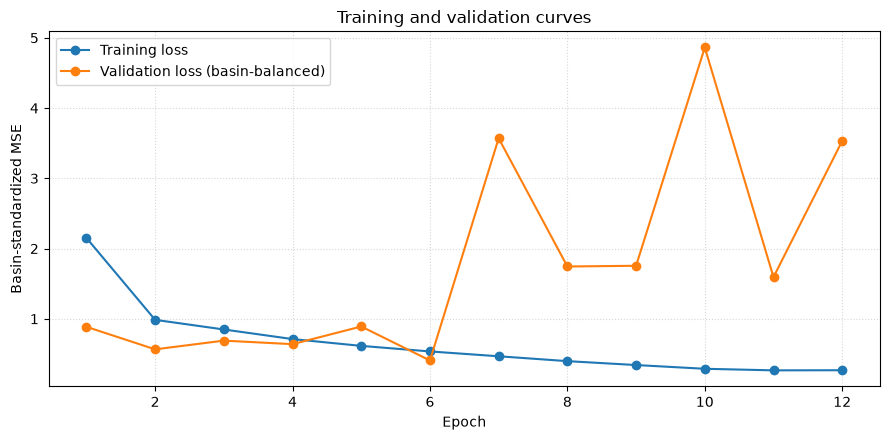

In [13]:
history_df = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training loss")
ax.plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="Validation loss (basin-balanced)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Basin-standardized MSE")
ax.set_title("Training and validation curves")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()


## 12. Evaluate the untouched final five years
Predictions are converted back to cfs using the global discharge scale fitted on the training years. Metrics are calculated only for valid target days. Positive percent bias means the model overpredicts total discharge; negative means underprediction.

In [14]:
def calculate_nse(obs, pred):
    denominator = np.sum((obs - np.mean(obs)) ** 2)
    return float(1.0 - np.sum((obs - pred) ** 2) / denominator) if denominator > 0 else np.nan


def calculate_kge(obs, pred):
    """Kling-Gupta efficiency (2009 form); NaN if its components are undefined."""
    if len(obs) < 2 or np.std(obs) == 0 or np.std(pred) == 0 or np.mean(obs) == 0:
        return np.nan
    corr = np.corrcoef(obs, pred)[0, 1]
    alpha = np.std(pred, ddof=0) / np.std(obs, ddof=0)
    beta = np.mean(pred) / np.mean(obs)
    if not np.isfinite([corr, alpha, beta]).all():
        return np.nan
    return float(1.0 - np.sqrt((corr - 1.0) ** 2 + (alpha - 1.0) ** 2 + (beta - 1.0) ** 2))


# Generate predictions for valid test samples. DataLoader order is deterministic (no shuffle).
model.eval()
pred_scaled_parts = []
target_scaled_parts = []
basin_idx_parts = []
target_idx_parts = []
with torch.no_grad():
    sample_offset = 0
    for batch in test_loader:
        x = batch["x"].to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            pred_scaled = model(x)
        pred_scaled_parts.append(pred_scaled.float().cpu().numpy().reshape(-1))
        target_scaled_parts.append(batch["y"].numpy().reshape(-1))
        basin_idx_parts.extend(batch["basin_idx"].numpy().astype(int).tolist())
        # Recover (basin index, target row index) from the dataset's deterministic sample list.
        batch_n = len(batch["basin_idx"])
        batch_samples = test_dataset.samples[sample_offset:sample_offset + batch_n]
        target_idx_parts.extend([t for _, t in batch_samples])
        sample_offset += batch_n

pred_scaled_all = np.concatenate(pred_scaled_parts)
target_scaled_all = np.concatenate(target_scaled_parts)
pred_cfs_all = pred_scaled_all * std_y + mean_y
obs_cfs_all = target_scaled_all * std_y + mean_y

# Assemble per-basin prediction frames and metrics.
all_results = {}
metric_rows = []
for basin_idx, basin in enumerate(basins):
    local_positions = [i for i, b_idx in enumerate(basin_idx_parts) if b_idx == basin_idx]
    local_target_indices = [target_idx_parts[i] for i in local_positions]
    local_pred = pred_cfs_all[local_positions]
    local_obs = obs_cfs_all[local_positions]

    result_df = basin["df"].iloc[local_target_indices][["Timestamp", TARGET_COL, "Precipitation_mm_day"]].copy()
    result_df = result_df.rename(columns={TARGET_COL: "Observed_Discharge_cfs"})
    result_df["Predicted_Discharge_cfs"] = local_pred
    result_df["Basin"] = basin["name"]
    all_results[basin["name"]] = result_df.reset_index(drop=True)

    obs = result_df["Observed_Discharge_cfs"].to_numpy(dtype=float)
    pred = result_df["Predicted_Discharge_cfs"].to_numpy(dtype=float)
    residual = pred - obs
    denominator = np.sum(obs)
    pbias = float(100.0 * np.sum(residual) / denominator) if abs(denominator) > 1e-12 else np.nan

    metric_rows.append({
        "Catchment": basin["name"],
        "Test Start Date": result_df["Timestamp"].min().date() if len(result_df) else None,
        "Test End Date": result_df["Timestamp"].max().date() if len(result_df) else None,
        "Valid Test Days": len(result_df),
        "NSE": calculate_nse(obs, pred) if len(obs) else np.nan,
        # R² uses the coefficient-of-determination definition (same formula as NSE here).
        "R²": calculate_nse(obs, pred) if len(obs) else np.nan,
        "KGE": calculate_kge(obs, pred) if len(obs) else np.nan,
        "RMSE (cfs)": float(np.sqrt(np.mean(residual ** 2))) if len(obs) else np.nan,
        "MAE (cfs)": float(np.mean(np.abs(residual))) if len(obs) else np.nan,
        "PBIAS (%)": pbias,
        "Mean observed (cfs)": float(np.mean(obs)) if len(obs) else np.nan,
        "Mean predicted (cfs)": float(np.mean(pred)) if len(pred) else np.nan,
    })

summary_df = pd.DataFrame(metric_rows).sort_values("NSE", ascending=True, na_position="last").reset_index(drop=True)
print("Test performance (lowest NSE first):")
display(summary_df.round(4))


Test performance (lowest NSE first):


,Catchment,Test Start Date,Test End Date,Valid Test Days,NSE,R²,KGE,RMSE (cfs),MAE (cfs),PBIAS (%),Mean observed (cfs),Mean predicted (cfs)
0,CAN_02CF007.csv,2015-01-02,2019-12-31,1825,-2.4483,-2.4483,-0.3935,322.9450,101.7134,27.5741,113.2002,144.4142
1,USA_01013500.csv,2015-01-02,2019-12-31,1825,0.0058,0.0058,-0.0838,2169.8563,1156.6030,-72.1073,1556.5322,434.1586
2,CAN_01AD003.csv,2015-01-02,2019-12-31,1825,0.1819,0.1819,0.0049,1367.2703,660.7234,-68.8742,901.6839,280.6565
3,USA_07068000.csv,2015-01-02,2019-12-30,1824,0.2223,0.2223,0.1393,5504.2901,1791.5720,-40.9620,3784.9709,2234.5704
4,CAN_01BJ003.csv,2015-01-02,2019-12-31,1825,0.5828,0.5828,0.5143,524.8282,217.0864,-19.7993,399.7121,320.5719
5,USA_03346000.csv,2015-01-02,2019-12-30,1824,0.5934,0.5934,0.7113,756.2848,275.6485,6.8990,395.8526,423.1623
6,USA_04216418.csv,2015-01-02,2019-12-30,1824,0.6263,0.6263,0.6362,120.8725,56.0054,-19.6113,135.6371,109.0369
7,USA_02015700.csv,2015-01-02,2019-12-30,1824,0.6630,0.6630,0.8252,144.6005,72.1594,2.7062,173.5073,178.2028
8,USA_01073000.csv,2015-01-02,2019-12-30,1824,0.7054,0.7054,0.7242,12.9757,9.5294,-22.6622,18.9998,14.6940
9,CAN_05BB001.csv,2015-01-02,2019-12-31,1825,0.8767,0.8767,0.8764,489.5837,283.7348,-7.0412,1326.1091,1232.7357


## 13. Save predictions, metrics, normalization statistics, and model
The exported metrics and predictions are intended for downstream analysis. The checkpoint records the feature names and key settings needed to interpret it. Normalization statistics contain training-only values.

In [15]:
# Combine the individual test predictions into one file.
if all_results:
    combined_predictions = pd.concat(all_results.values(), ignore_index=True)
else:
    combined_predictions = pd.DataFrame()

summary_df.to_csv(METRICS_PATH, index=False)
combined_predictions.to_csv(PREDICTIONS_PATH, index=False)

np.savez(
    NORMALIZATION_PATH,
    mean_x=mean_x,
    std_x=std_x,
    mean_y=np.array(mean_y),
    std_y=np.array(std_y),
    met_cols=np.array(MET_COLS),
    basin_names=np.array([b["name"] for b in basins]),
    basin_train_std_cfs=np.array([basin_train_std_cfs[b["name"]] for b in basins]),
)

checkpoint = {
    "model_type": "meteorology_only_multibasin_lstm",
    "model_state_dict": model.state_dict(),
    "dynamic_dim": len(MET_COLS),
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "met_cols": MET_COLS,
    "target_col": TARGET_COL,
    "lookback_days": LOOKBACK_DAYS,
    "use_target_day_meteorology": USE_TARGET_DAY_METEOROLOGY,
    "best_epoch": best_epoch,
    "best_validation_loss": best_val_loss,
    "basin_train_std_cfs": basin_train_std_cfs,
}
torch.save(checkpoint, MODEL_PATH)

print("Saved files:")
for path in [MODEL_PATH, NORMALIZATION_PATH, METRICS_PATH, PREDICTIONS_PATH]:
    print(f"  {path} ({Path(path).stat().st_size:,} bytes)")


Saved files:
  multibasin_lstm_model_v2.pth (284,730 bytes)
  multibasin_norm_stats_v2.npz (3,258 bytes)
  multibasin_test_metrics_v2.csv (2,091 bytes)
  multibasin_test_predictions_v2.csv (1,125,574 bytes)


## 14. Plot observed vs. predicted hydrographs
Use this helper to visually inspect any basin or date range. Hydrographs are especially useful for identifying peak underestimation, timing errors, seasonal bias, and low-flow mismatch that a single NSE value cannot explain.

In [18]:
def plot_basin_hydrograph(basin_name, start_date=None, end_date=None, show_precipitation=True):
    """Plot observations and model predictions for one basin within an optional date range."""
    if basin_name not in all_results:
        raise KeyError(f"Unknown basin {basin_name!r}. Choose one of: {list(all_results)}")
    frame = all_results[basin_name].copy()
    if start_date is not None:
        frame = frame[frame["Timestamp"] >= pd.Timestamp(start_date)]
    if end_date is not None:
        frame = frame[frame["Timestamp"] <= pd.Timestamp(end_date)]
    if frame.empty:
        print("No valid test predictions in the requested date range.")
        return

    fig, ax1 = plt.subplots(figsize=(15, 5.5))
    ax1.plot(frame["Timestamp"], frame["Observed_Discharge_cfs"], label="Observed discharge", linewidth=1.2)
    ax1.plot(frame["Timestamp"], frame["Predicted_Discharge_cfs"], label="Predicted discharge", linewidth=1.1, linestyle="--")
    ax1.set_xlabel("Date")
    ax1.set_ylabel("Discharge (cfs)")
    ax1.grid(True, linestyle=":", alpha=0.4)
    ax1.legend(loc="upper left")

    if show_precipitation:
        ax2 = ax1.twinx()
        ax2.bar(frame["Timestamp"], frame["Precipitation_mm_day"], width=1.0, alpha=0.22, label="Precipitation")
        ax2.set_ylabel("Precipitation (mm/day)")
        ax2.set_ylim(max(float(frame["Precipitation_mm_day"].max()), 1.0) * 3.0, 0)

    ax1.set_title(f"{basin_name}: observed vs predicted discharge")
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

# The interactive basin explorer is displayed in the final section of this notebook.


## 15. How to interpret the outputs

- **NSE**: 1 is perfect; 0 means performance comparable to predicting the observed mean; negative values are worse than that baseline.
- **R²**: squared correlation, describing association rather than bias or peak accuracy. Read it together with NSE and PBIAS.
- **KGE**: combines correlation, variability ratio, and mean ratio; values near 1 are better.
- **RMSE and MAE**: absolute errors in cfs; their sizes are not directly comparable between differently sized catchments.
- **PBIAS**: positive means total predicted discharge is too high; negative means too low.

### Important checks before comparing this run with the previous notebook

1. This notebook uses a three-year validation period, early stopping, training-only scalers and basin standard deviations, and basin-balanced sampling. It is not an exact reproduction of the earlier training recipe.
2. By default, target-day meteorology is included, so this is a same-day rainfall–runoff simulation. For a strict one-day-ahead forecast, set `USE_TARGET_DAY_METEOROLOGY = False` and rerun the notebook from the top.
3. Incomplete forcing days are not used in windows when `Forcing_Hour_Count` is present. Missing discharge is not imputed; rows with missing targets are skipped.
4. The final five years remain the held-out test set. Do not use test NSE to tune hyperparameters repeatedly; use validation loss for model selection.

## 16. Interactive basin explorer and performance comparison

This final section creates interactive Plotly charts from the **held-out test predictions**:

1. **Hydrograph explorer:** choose a basin from the dropdown, compare observed and predicted discharge, and toggle precipitation by clicking its legend entry. Hover to inspect daily values, zoom or pan, drag the date-range slider, or use the quick buttons to focus on one year, two years, five years, or the full test period. The chart title includes that basin's test metrics.
2. **Performance comparison:** compare basin NSE values in one chart. Hover over a bar for NSE, KGE, RMSE, MAE and PBIAS. Negative NSE indicates performance worse than using the observed test-period mean as the prediction.

The charts use `all_results` and `summary_df` created earlier. They do not retrain the model or change any test metrics. Plotly is commonly available in Colab; if it is missing, run `%pip install plotly` in a separate cell and rerun this section.


In [17]:
# Plotly adds hover details, zoom/pan, a date-range slider, and an in-chart basin dropdown.
try:
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
except ImportError as exc:
    raise ImportError(
        "This interactive section requires Plotly. In a new notebook cell, run `%pip install plotly`, "
        "restart the runtime if requested, and rerun this section."
    ) from exc

if not all_results:
    raise RuntimeError("No test predictions are available. Run the evaluation section before this one.")

# Use the results table's order (lowest NSE first), but include only basins with valid test predictions.
interactive_basins = [
    name for name in summary_df["Catchment"].tolist()
    if name in all_results and not all_results[name].empty
]
if not interactive_basins:
    raise RuntimeError("The evaluation produced no non-empty per-basin test prediction frames.")

metric_lookup = summary_df.drop_duplicates("Catchment").set_index("Catchment")


def _metric_text(basin_name, column, digits=3):
    """Format a metric for chart titles and tooltips, handling undefined metrics safely."""
    try:
        value = float(metric_lookup.loc[basin_name, column])
    except (KeyError, TypeError, ValueError):
        return "n/a"
    return f"{value:.{digits}f}" if np.isfinite(value) else "n/a"


def _hydrograph_title(basin_name):
    """Build a title containing the basin name and its held-out test metrics."""
    return (
        f"<b>{basin_name}: observed vs. predicted discharge</b><br>"
        f"NSE {_metric_text(basin_name, 'NSE')} &nbsp;|&nbsp; "
        f"KGE {_metric_text(basin_name, 'KGE')} &nbsp;|&nbsp; "
        f"RMSE {_metric_text(basin_name, 'RMSE (cfs)')} cfs &nbsp;|&nbsp; "
        f"MAE {_metric_text(basin_name, 'MAE (cfs)')} cfs &nbsp;|&nbsp; "
        f"PBIAS {_metric_text(basin_name, 'PBIAS (%)')}%"
    )


# Build a single figure containing a trace group for every basin. The dropdown switches groups;
# Plotly keeps all interaction client-side, so changing the selected basin is immediate.
hydro_fig = make_subplots(specs=[[{"secondary_y": True}]])
trace_indices_by_basin = {}

for basin_index, basin_name in enumerate(interactive_basins):
    frame = all_results[basin_name].copy().sort_values("Timestamp")
    visible = basin_index == 0
    start_trace = len(hydro_fig.data)

    hydro_fig.add_trace(
        go.Scatter(
            x=frame["Timestamp"],
            y=frame["Observed_Discharge_cfs"],
            mode="lines",
            name="Observed discharge",
            line={"width": 1.5},
            visible=visible,
            hovertemplate="Date: %{x|%Y-%m-%d}<br>Observed: %{y:,.2f} cfs<extra></extra>",
        ),
        secondary_y=False,
    )
    hydro_fig.add_trace(
        go.Scatter(
            x=frame["Timestamp"],
            y=frame["Predicted_Discharge_cfs"],
            mode="lines",
            name="Predicted discharge",
            line={"width": 1.4, "dash": "dash"},
            visible=visible,
            hovertemplate="Date: %{x|%Y-%m-%d}<br>Predicted: %{y:,.2f} cfs<extra></extra>",
        ),
        secondary_y=False,
    )
    hydro_fig.add_trace(
        go.Bar(
            x=frame["Timestamp"],
            y=frame["Precipitation_mm_day"],
            name="Precipitation",
            opacity=0.24,
            marker_line_width=0,
            visible=visible,
            hovertemplate="Date: %{x|%Y-%m-%d}<br>Precipitation: %{y:.2f} mm/day<extra></extra>",
        ),
        secondary_y=True,
    )
    trace_indices_by_basin[basin_name] = list(range(start_trace, len(hydro_fig.data)))

# Each menu item makes only that basin's three traces visible and resets the axes for its date span.
basin_buttons = []
number_of_traces = len(hydro_fig.data)
for basin_name in interactive_basins:
    visible = [False] * number_of_traces
    for trace_index in trace_indices_by_basin[basin_name]:
        visible[trace_index] = True
    basin_buttons.append({
        "label": basin_name,
        "method": "update",
        "args": [
            {"visible": visible},
            {
                "title": {"text": _hydrograph_title(basin_name)},
                "xaxis": {"autorange": True},
                "yaxis": {"autorange": True},
                "yaxis2": {"autorange": "reversed"},
            },
        ],
    })

initial_basin = interactive_basins[0]
hydro_fig.update_layout(
    title={"text": _hydrograph_title(initial_basin), "x": 0.02, "xanchor": "left"},
    height=690,
    template="plotly_white",
    hovermode="x unified",
    barmode="overlay",
    margin={"l": 80, "r": 85, "t": 155, "b": 70},
    legend={"orientation": "h", "yanchor": "bottom", "y": 1.02, "x": 0.01},
    updatemenus=[{
        "type": "dropdown",
        "direction": "down",
        "x": 0.01,
        "xanchor": "left",
        "y": 1.26,
        "yanchor": "top",
        "showactive": True,
        "buttons": basin_buttons,
    }],
)
hydro_fig.update_xaxes(
    title_text="Date",
    rangeslider={"visible": True, "thickness": 0.09},
    rangeselector={
        "x": 1.0,
        "xanchor": "right",
        "y": 1.15,
        "buttons": [
            {"count": 1, "label": "1Y", "step": "year", "stepmode": "backward"},
            {"count": 2, "label": "2Y", "step": "year", "stepmode": "backward"},
            {"count": 5, "label": "5Y", "step": "year", "stepmode": "backward"},
            {"step": "all", "label": "Full test"},
        ],
    },
)
hydro_fig.update_yaxes(title_text="Discharge (cfs)", secondary_y=False, rangemode="tozero")
hydro_fig.update_yaxes(
    title_text="Precipitation (mm/day; inverted axis)",
    secondary_y=True,
    autorange="reversed",
    rangemode="tozero",
)

print("Interactive hydrograph explorer: choose a basin with the dropdown; click 'Precipitation' in the legend to show/hide rainfall.")
hydro_fig.show()


# A second chart makes cross-basin performance differences easier to compare.
performance_plot_df = summary_df.copy()
performance_plot_df = performance_plot_df[np.isfinite(pd.to_numeric(performance_plot_df["NSE"], errors="coerce"))]
performance_plot_df = performance_plot_df.sort_values("NSE", ascending=True)

if performance_plot_df.empty:
    print("No finite NSE values are available for the performance comparison chart.")
else:
    hover_text = []
    for _, row in performance_plot_df.iterrows():
        hover_text.append(
            f"NSE: {row['NSE']:.3f}<br>"
            f"KGE: {_metric_text(row['Catchment'], 'KGE')}<br>"
            f"RMSE: {_metric_text(row['Catchment'], 'RMSE (cfs)')} cfs<br>"
            f"MAE: {_metric_text(row['Catchment'], 'MAE (cfs)')} cfs<br>"
            f"PBIAS: {_metric_text(row['Catchment'], 'PBIAS (%)')}%"
        )

    performance_fig = go.Figure(
        data=[go.Bar(
            x=performance_plot_df["NSE"],
            y=performance_plot_df["Catchment"],
            orientation="h",
            text=[f"{value:.3f}" for value in performance_plot_df["NSE"]],
            textposition="outside",
            customdata=np.array(hover_text, dtype=object),
            hovertemplate="%{y}<br>%{customdata}<extra></extra>",
        )]
    )
    performance_fig.add_vline(x=0, line_dash="dash", line_width=1, annotation_text="NSE = 0 baseline")
    performance_fig.update_layout(
        title="Held-out test performance by basin (NSE; lower scores first)",
        xaxis_title="Nash–Sutcliffe Efficiency (NSE)",
        yaxis_title="Basin",
        height=max(430, 42 * len(performance_plot_df)),
        template="plotly_white",
        margin={"l": 180, "r": 55, "t": 75, "b": 65},
        showlegend=False,
    )
    performance_fig.update_yaxes(autorange="reversed")
    performance_fig.show()


ImportError: This interactive section requires Plotly. In a new notebook cell, run `%pip install plotly`, restart the runtime if requested, and rerun this section.